In [14]:
from pathlib import Path
import pandas as pd
import numpy as np
import pandas as pd
data_file_name = Path("data") / "raw" / "student-por.csv"

project_root = next(
    (
        folder
        for folder in (Path.cwd(), *Path.cwd().parents)
        if (folder / data_file_name).exists()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Could not locate data/raw/student-por.csv. "
        "Check that the dataset is inside the project's data/raw folder."
    )

data_file = project_root / data_file_name
students = pd.read_csv(data_file)

print(f"Dataset file: {data_file}")
print(f"Number of student records: {students.shape[0]}")
print(f"Number of columns: {students.shape[1]}")

Dataset file: C:\Users\DELL\Desktop\student-performance-xai\data\raw\student-por.csv
Number of student records: 649
Number of columns: 33


In [6]:
students["passed"] = (students["G3"] >= 10).astype(int)

pass_count = (students["passed"] == 1).sum()
fail_count = (students["passed"] == 0).sum()

print(f"Pass: {pass_count}")
print(f"Fail: {fail_count}")
print(f"Total: {len(students)}")
print("\nPass/Fail percentages:")
print(
    (students["passed"].value_counts(normalize=True) * 100)
    .rename(index={1: "Pass", 0: "Fail"})
    .round(1)
)

Pass: 549
Fail: 100
Total: 649

Pass/Fail percentages:
passed
Pass    84.6
Fail    15.4
Name: proportion, dtype: float64


In [7]:
print("Missing values in each column:")
print(students.isna().sum().sort_values(ascending=False).head(10))

Missing values in each column:
school     0
sex        0
age        0
address    0
famsize    0
Pstatus    0
Medu       0
Fedu       0
Mjob       0
Fjob       0
dtype: int64


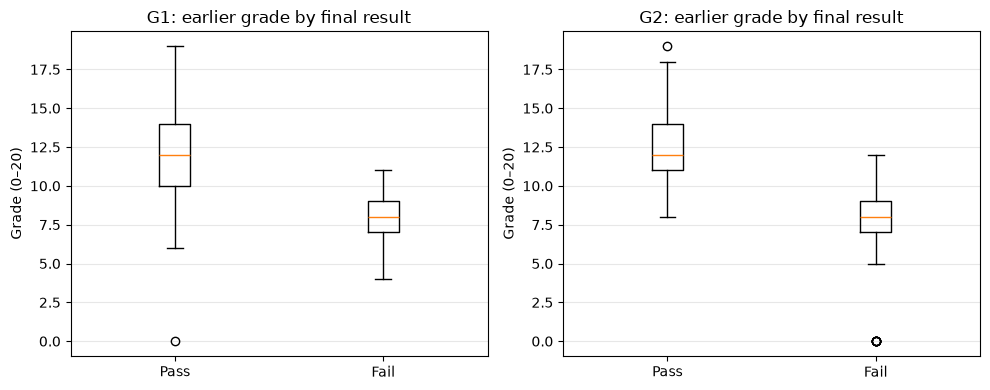

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, grade in zip(axes, ["G1", "G2"]):
    pass_grades = students.loc[students["passed"] == 1, grade]
    fail_grades = students.loc[students["passed"] == 0, grade]

    ax.boxplot([pass_grades, fail_grades], tick_labels=["Pass", "Fail"])
    ax.set_title(f"{grade}: earlier grade by final result")
    ax.set_ylabel("Grade (0–20)")
    ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
X = students.drop(columns=["G3", "passed"])
y = students["passed"]

print(f"Input rows and columns: {X.shape}")
print(f"Outcome rows: {y.shape[0]}")
print(f"Are G1 and G2 included? {'G1' in X.columns and 'G2' in X.columns}")
print(f"Is G3 excluded? {'G3' not in X.columns}")
print(f"Are Pass and Fail labels in y? {y.value_counts().to_dict()}")
print()
print(X.columns.tolist())

Input rows and columns: (649, 32)
Outcome rows: 649
Are G1 and G2 included? True
Is G3 excluded? True
Are Pass and Fail labels in y? {1: 549, 0: 100}

['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


In [39]:
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

y_train_fail = (y_train == 0).astype(int)

def make_subset_preprocessor(fit_data):
    """Encode categorical columns and pass numeric columns through."""
    categorical = fit_data.select_dtypes(
        include=["object", "str"]
    ).columns.tolist()

    numeric = [
        column for column in fit_data.columns
        if column not in categorical
    ]

    return ColumnTransformer(
        transformers=[
            (
                "categories",
                OneHotEncoder(
                    handle_unknown="ignore",
                    drop="if_binary",
                ),
                categorical,
            ),
            ("numbers", "passthrough", numeric),
        ]
    )

cross_validator = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42,
)
folds = list(cross_validator.split(X_train, y_train_fail))

n_trees = 300
n_repeats = 5
permutation_rows = []

for fold_number, (fit_indices, validation_indices) in enumerate(
    folds, start=1
):
    X_fit = X_train.iloc[fit_indices]
    X_validation = X_train.iloc[validation_indices]
    y_fit = y_train_fail.iloc[fit_indices]
    y_validation = y_train_fail.iloc[validation_indices]

    model = Pipeline(
        steps=[
            ("preprocessor", make_subset_preprocessor(X_fit)),
            (
                "classifier",
                RandomForestClassifier(
                    n_estimators=n_trees,
                    class_weight="balanced",
                    random_state=42,
                    n_jobs=-1,
                ),
            ),
        ]
    )

    model.fit(X_fit, y_fit)

    result = permutation_importance(
        estimator=model,
        X=X_validation,
        y=y_validation,
        scoring="average_precision",
        n_repeats=n_repeats,
        random_state=42 + fold_number,
        n_jobs=1,
    )

    for feature_position, feature_name in enumerate(X_train.columns):
        permutation_rows.append(
            {
                "feature": feature_name,
                "fold": fold_number,
                "mean_ap_drop": result.importances_mean[feature_position],
            }
        )

permutation_fold_results = pd.DataFrame(permutation_rows)

permutation_summary = (
    permutation_fold_results
    .groupby("feature")
    .agg(
        mean_ap_drop=("mean_ap_drop", "mean"),
        std_ap_drop=("mean_ap_drop", "std"),
        positive_folds_percent=(
            "mean_ap_drop",
            lambda values: (values > 0).mean() * 100,
        ),
    )
    .sort_values("mean_ap_drop", ascending=False)
)

print("\nPermutation importance summary:")
print(permutation_summary.round(4).to_string())


Permutation importance summary:
            mean_ap_drop  std_ap_drop  positive_folds_percent
feature                                                      
G2                0.2044       0.0375                   100.0
G1                0.1988       0.0395                   100.0
failures          0.0163       0.0184                    80.0
school            0.0138       0.0265                    68.0
Fjob              0.0058       0.0155                    60.0
famrel            0.0051       0.0099                    76.0
Walc              0.0038       0.0118                    56.0
famsize           0.0019       0.0070                    52.0
Mjob              0.0018       0.0092                    60.0
reason            0.0010       0.0138                    56.0
Medu              0.0007       0.0111                    52.0
Dalc              0.0005       0.0112                    32.0
romantic          0.0001       0.0050                    32.0
nursery          -0.0001       0.0072

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print(f"Training records: {len(X_train)}")
print(f"Test records: {len(X_test)}")

print("\nTraining labels (0 = Fail, 1 = Pass):")
print(y_train.value_counts().sort_index())

print("\nTest labels (0 = Fail, 1 = Pass):")
print(y_test.value_counts().sort_index())

Training records: 519
Test records: 130

Training labels (0 = Fail, 1 = Pass):
passed
0     80
1    439
Name: count, dtype: int64

Test labels (0 = Fail, 1 = Pass):
passed
0     20
1    110
Name: count, dtype: int64


In [21]:
categorical_columns = X_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

numeric_columns = [
    column for column in X_train.columns
    if column not in categorical_columns
]

print(f"Categorical columns ({len(categorical_columns)}):")
print(categorical_columns)

print(f"\nNumeric columns ({len(numeric_columns)}):")
print(numeric_columns)

Categorical columns (17):
['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Numeric columns (15):
['age', 'Medu', 'Fedu', 'traveltime', 'studytime', 'failures', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2']


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

def make_preprocessor(scale_numeric=False):
    numeric_transformer = (
        StandardScaler() if scale_numeric else "passthrough"
    )

    return ColumnTransformer(
        transformers=[
            (
                "categories",
                OneHotEncoder(handle_unknown="ignore", drop="if_binary"),
                categorical_columns,
            ),
            ("numbers", numeric_transformer, numeric_columns),
        ]
    )

preprocessor_preview = make_preprocessor()
X_train_encoded_preview = preprocessor_preview.fit_transform(X_train)

print(f"Input columns before encoding: {X_train.shape[1]}")
print(f"Columns after encoding: {X_train_encoded_preview.shape[1]}")

Input columns before encoding: 32
Columns after encoding: 45


In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    fbeta_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

y_train_fail = (y_train == 0).astype(int)

cross_validator = RepeatedStratifiedKFold(
    n_splits=5,
    n_repeats=5,
    random_state=42,
)

model_names = ["Logistic Regression", "Random Forest", "XGBoost"]
fold_results = []

for fold_number, (fit_indices, validation_indices) in enumerate(
    cross_validator.split(X_train, y_train_fail),
    start=1,
):
    X_fit = X_train.iloc[fit_indices]
    X_validation = X_train.iloc[validation_indices]
    y_fit = y_train_fail.iloc[fit_indices]
    y_validation = y_train_fail.iloc[validation_indices]

    for model_name in model_names:
        if model_name == "Logistic Regression":
            classifier = LogisticRegression(
                class_weight="balanced",
                max_iter=3000,
                random_state=42,
            )
        elif model_name == "Random Forest":
            classifier = RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
                n_jobs=-1,
            )
        else:
            fail_count = int(y_fit.sum())
            pass_count = len(y_fit) - fail_count
            classifier = XGBClassifier(
                n_estimators=300,
                max_depth=3,
                learning_rate=0.05,
                subsample=0.9,
                colsample_bytree=0.9,
                scale_pos_weight=pass_count / fail_count,
                eval_metric="logloss",
                random_state=42,
                n_jobs=-1,
            )

        pipeline = Pipeline(
            steps=[
                (
                    "preprocessor",
                    make_preprocessor(
                        scale_numeric=(model_name == "Logistic Regression")
                    ),
                ),
                ("classifier", classifier),
            ]
        )

        pipeline.fit(X_fit, y_fit)
        fail_index = list(
            pipeline.named_steps["classifier"].classes_
        ).index(1)
        fail_scores = pipeline.predict_proba(X_validation)[:, fail_index]
        predicted_fail = (fail_scores >= 0.50).astype(int)

        fold_results.append(
            {
                "model": model_name,
                "fold": fold_number,
                "fail_average_precision": average_precision_score(
                    y_validation, fail_scores
                ),
                "fail_recall": recall_score(
                    y_validation, predicted_fail, zero_division=0
                ),
                "fail_precision": precision_score(
                    y_validation, predicted_fail, zero_division=0
                ),
                "fail_f2": fbeta_score(
                    y_validation,
                    predicted_fail,
                    beta=2,
                    zero_division=0,
                ),
            }
        )

cv_results = pd.DataFrame(fold_results)

summary = cv_results.groupby("model").agg(
    fail_average_precision_mean=("fail_average_precision", "mean"),
    fail_recall_mean=("fail_recall", "mean"),
    fail_precision_mean=("fail_precision", "mean"),
    fail_f2_mean=("fail_f2", "mean"),
)

summary.sort_values(
    "fail_average_precision_mean",
    ascending=False,
).round(3)

,fail_average_precision_mean,fail_recall_mean,fail_precision_mean,fail_f2_mean
model,,,,
XGBoost,0.889,0.835,0.802,0.825
Random Forest,0.880,0.835,0.788,0.822
Logistic Regression,0.837,0.855,0.635,0.796


In [28]:
from sklearn.model_selection import train_test_split

y_train_fail_all = (y_train == 0).astype(int)

X_fit, X_validation, y_fit, y_validation = train_test_split(
    X_train,
    y_train_fail_all,
    test_size=0.25,
    random_state=43,
    stratify=y_train_fail_all,
)

print(f"Records used to fit models: {len(X_fit)}")
print(f"Records used to compare cutoffs: {len(X_validation)}")
print(f"Actual Fails in validation group: {int(y_validation.sum())}")

Records used to fit models: 389
Records used to compare cutoffs: 130
Actual Fails in validation group: 20


In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import fbeta_score, precision_score, recall_score
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier

candidate_models = {
    "Logistic Regression": LogisticRegression(
        class_weight="balanced",
        max_iter=3000,
        random_state=42,
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1,
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.9,
        colsample_bytree=0.9,
        scale_pos_weight=(len(y_fit) - int(y_fit.sum())) / int(y_fit.sum()),
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    ),
}

validation_scores = {}
rows = []

for model_name, classifier in candidate_models.items():
    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                make_preprocessor(
                    scale_numeric=(model_name == "Logistic Regression")
                ),
            ),
            ("classifier", classifier),
        ]
    )

    pipeline.fit(X_fit, y_fit)
    fail_scores = pipeline.predict_proba(X_validation)[:, 1]
    validation_scores[model_name] = fail_scores

    for cutoff in [0.10, 0.15, 0.20, 0.25, 0.30, 0.35,
                   0.40, 0.45, 0.50, 0.55, 0.60, 0.65,
                   0.70, 0.75, 0.80, 0.85, 0.90]:
        predicted_fail = (fail_scores >= cutoff).astype(int)

        rows.append({
            "model": model_name,
            "cutoff": cutoff,
            "fails_caught": int(((y_validation == 1) & (predicted_fail == 1)).sum()),
            "fails_missed": int(((y_validation == 1) & (predicted_fail == 0)).sum()),
            "false_alarms": int(((y_validation == 0) & (predicted_fail == 1)).sum()),
            "precision": precision_score(y_validation, predicted_fail, zero_division=0),
            "recall": recall_score(y_validation, predicted_fail, zero_division=0),
            "F2": fbeta_score(y_validation, predicted_fail, beta=2, zero_division=0),
        })

threshold_results = pd.DataFrame(rows)

best_cutoffs = (
    threshold_results
    .sort_values(
        ["model", "F2", "recall", "precision", "cutoff"],
        ascending=[True, False, False, False, False],
    )
    .groupby("model", as_index=False)
    .first()
    .sort_values("F2", ascending=False)
)

print("Best validation cutoff for each model (F2 prioritizes catching Fails):")
best_cutoffs[
    ["model", "cutoff", "fails_caught", "fails_missed",
     "false_alarms", "precision", "recall", "F2"]
].round(3)

Best validation cutoff for each model (F2 prioritizes catching Fails):


,model,cutoff,fails_caught,fails_missed,false_alarms,precision,recall,F2
1,Random Forest,0.35,19,1,9,0.679,0.95,0.880
0,Logistic Regression,0.20,19,1,12,0.613,0.95,0.856
2,XGBoost,0.75,17,3,3,0.850,0.85,0.850


In [30]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    fbeta_score,
    precision_score,
    recall_score,
)
from sklearn.pipeline import Pipeline

y_train_fail = (y_train == 0).astype(int)
y_test_fail = (y_test == 0).astype(int)

final_rf = Pipeline(
    steps=[
        ("preprocessor", make_preprocessor()),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]
)

final_rf.fit(X_train, y_train_fail)

fail_scores = final_rf.predict_proba(X_test)[:, 1]
cutoff = 0.35
predicted_fail = (fail_scores >= cutoff).astype(int)

print("Confusion matrix (rows = actual [Pass, Fail], columns = predicted [Pass, Fail]):")
print(confusion_matrix(y_test_fail, predicted_fail, labels=[0, 1]))

print(f"\nAccuracy: {accuracy_score(y_test_fail, predicted_fail):.3f}")
print(f"Fail precision: {precision_score(y_test_fail, predicted_fail, zero_division=0):.3f}")
print(f"Fail recall: {recall_score(y_test_fail, predicted_fail, zero_division=0):.3f}")
print(f"Fail F2: {fbeta_score(y_test_fail, predicted_fail, beta=2, zero_division=0):.3f}")
print(f"Fail average precision: {average_precision_score(y_test_fail, fail_scores):.3f}")

Confusion matrix (rows = actual [Pass, Fail], columns = predicted [Pass, Fail]):
[[94 16]
 [ 3 17]]

Accuracy: 0.854
Fail precision: 0.515
Fail recall: 0.850
Fail F2: 0.752
Fail average precision: 0.643


C:\Users\DELL\Desktop\student-performance-xai\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Example test profile number: 1
Model prediction: Pass
Model Fail score: 0.7%


,feature,student_value,contribution_to_Fail_score,direction
31,G2,12,-0.058589,Away from Fail
30,G1,12,-0.046917,Away from Fail
0,school,GP,-0.015836,Away from Fail
22,failures,0,-0.009289,Away from Fail
14,higher,yes,-0.006618,Away from Fail
25,goout,3,-0.006512,Away from Fail
26,Dalc,1,-0.006102,Away from Fail
24,freetime,3,-0.003584,Away from Fail
19,Fedu,4,-0.003293,Away from Fail
11,paid,yes,0.006857,Toward Fail


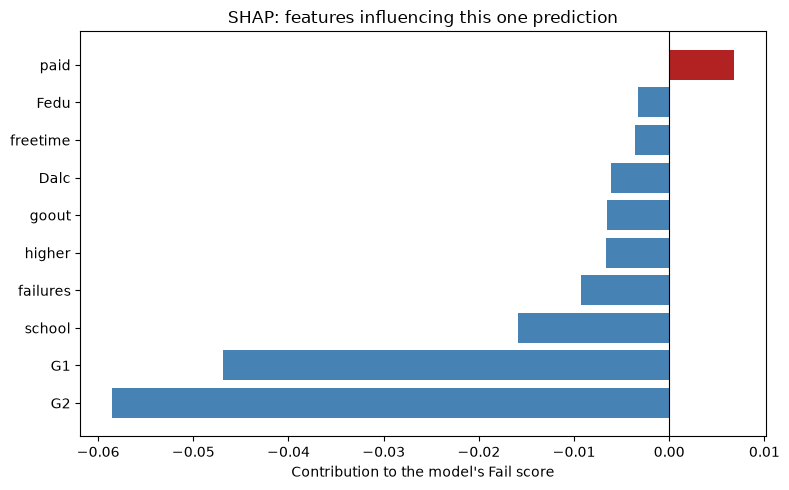

In [31]:
import numpy as np
import shap
import matplotlib.pyplot as plt
from scipy import sparse

example_number = 0
profile = X_test.iloc[[example_number]]

preprocessor = final_rf.named_steps["preprocessor"]
classifier = final_rf.named_steps["classifier"]

encoded_profile = preprocessor.transform(profile)
background = preprocessor.transform(X_train.iloc[:100])

if sparse.issparse(encoded_profile):
    encoded_profile = encoded_profile.toarray()
if sparse.issparse(background):
    background = background.toarray()

explainer = shap.TreeExplainer(
    classifier,
    data=background,
    feature_perturbation="interventional",
    model_output="probability",
)
raw_shap_values = explainer.shap_values(encoded_profile)

if isinstance(raw_shap_values, list):
    encoded_contributions = np.asarray(raw_shap_values[1])[0]
else:
    values_array = np.asarray(raw_shap_values)
    if values_array.ndim == 3:
        encoded_contributions = values_array[0, :, 1]
    elif values_array.ndim == 2:
        encoded_contributions = values_array[0]
    else:
        raise ValueError(f"Unexpected SHAP output shape: {values_array.shape}")

categorical_columns = preprocessor.transformers_[0][2]
numeric_columns = preprocessor.transformers_[1][2]
encoder = preprocessor.named_transformers_["categories"]
grouped_contributions = {}

position = preprocessor.output_indices_["categories"].start
for column, categories, dropped_category in zip(
    categorical_columns,
    encoder.categories_,
    encoder.drop_idx_,
):
    encoded_width = len(categories) - int(dropped_category is not None)
    next_position = position + encoded_width

    grouped_contributions[column] = float(
        encoded_contributions[position:next_position].sum()
    )
    position = next_position
numeric_start = preprocessor.output_indices_["numbers"].start
for offset, column in enumerate(numeric_columns):
    grouped_contributions[column] = float(
        encoded_contributions[numeric_start + offset]
    )

shap_table = pd.DataFrame(
    [
        {
            "feature": column,
            "student_value": profile.iloc[0][column],
            "contribution_to_Fail_score": contribution,
            "direction": "Toward Fail" if contribution > 0 else "Away from Fail",
        }
        for column, contribution in grouped_contributions.items()
    ]
)
shap_table["absolute_contribution"] = shap_table[
    "contribution_to_Fail_score"
].abs()
shap_top10 = shap_table.nlargest(10, "absolute_contribution").sort_values(
    "contribution_to_Fail_score"
)

print(f"Example test profile number: {example_number + 1}")
print(f"Model prediction: {'Fail' if fail_scores[example_number] >= cutoff else 'Pass'}")
print(f"Model Fail score: {fail_scores[example_number]:.1%}")
display(shap_top10.drop(columns="absolute_contribution"))

plt.figure(figsize=(8, 5))
colors = [
    "firebrick" if value > 0 else "steelblue"
    for value in shap_top10["contribution_to_Fail_score"]
]
plt.barh(
    shap_top10["feature"],
    shap_top10["contribution_to_Fail_score"],
    color=colors,
)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Contribution to the model's Fail score")
plt.title("SHAP: features influencing this one prediction")
plt.tight_layout()
plt.show()

In [32]:
from lime.lime_tabular import LimeTabularExplainer

categorical_columns = X_train.select_dtypes(
    include=["object", "str"]
).columns.tolist()

encoder = final_rf.named_steps["preprocessor"].named_transformers_["categories"]
categories_by_column = dict(zip(categorical_columns, encoder.categories_))

category_to_code = {
    column: {category: code for code, category in enumerate(categories)}
    for column, categories in categories_by_column.items()
}

X_train_lime = X_train.copy()
for column in categorical_columns:
    X_train_lime[column] = X_train_lime[column].map(category_to_code[column])

categorical_positions = [
    X_train.columns.get_loc(column) for column in categorical_columns
]

categorical_names = {
    X_train.columns.get_loc(column): [
        str(category) for category in categories_by_column[column]
    ]
    for column in categorical_columns
}

def predict_from_lime(rows):
    lime_profiles = pd.DataFrame(rows, columns=X_train.columns)

    for column in categorical_columns:
        position = X_train.columns.get_loc(column)
        categories = categories_by_column[column]
        codes = np.rint(lime_profiles[column]).astype(int)

        if ((codes < 0) | (codes >= len(categories))).any():
            raise ValueError(f"Unexpected category code for {column}")

        lime_profiles[column] = [categories[code] for code in codes]

    return final_rf.predict_proba(lime_profiles)

lime_explainer = LimeTabularExplainer(
    training_data=X_train_lime.to_numpy(dtype=float),
    feature_names=list(X_train.columns),
    categorical_features=categorical_positions,
    categorical_names=categorical_names,
    class_names=["Pass", "Fail"],
    mode="classification",
    random_state=42,
)

lime_explanation = lime_explainer.explain_instance(
    data_row=X_test.iloc[example_number].copy().pipe(
        lambda row: pd.Series(
            [
                category_to_code[column][row[column]]
                if column in categorical_columns
                else row[column]
                for column in X_train.columns
            ],
            index=X_train.columns,
        )
    ).to_numpy(dtype=float),
    predict_fn=predict_from_lime,
    labels=(1,),
    num_features=10,
    num_samples=1000,
)

lime_rows = lime_explanation.as_map()[1]

lime_table = pd.DataFrame(
    [
        {
            "feature": X_train.columns[feature_index],
            "student_value": profile.iloc[0][X_train.columns[feature_index]],
            "contribution_to_Fail_score": weight,
            "direction": "Toward Fail" if weight > 0 else "Away from Fail",
        }
        for feature_index, weight in lime_rows
    ]
)

lime_table["absolute_contribution"] = lime_table[
    "contribution_to_Fail_score"
].abs()

print(f"LIME local fit (R²): {lime_explanation.score:.3f}")
display(
    lime_table.nlargest(10, "absolute_contribution")
    .drop(columns="absolute_contribution")
)

LIME local fit (R²): 0.257


,feature,student_value,contribution_to_Fail_score,direction
0,failures,0,-0.119649,Away from Fail
1,G2,12,-0.115211,Away from Fail
2,G1,12,-0.109023,Away from Fail
3,school,GP,-0.079943,Away from Fail
4,higher,yes,-0.077266,Away from Fail
5,paid,yes,-0.053603,Away from Fail
6,Fedu,4,-0.026077,Away from Fail
7,activities,yes,-0.018306,Away from Fail
8,Mjob,services,0.017921,Toward Fail
9,Dalc,1,-0.012248,Away from Fail


In [33]:
shap_features = set(shap_top10["feature"])
lime_features = set(lime_table["feature"])

shared_features = shap_features & lime_features
all_features = shap_features | lime_features
overlap = len(shared_features) / len(all_features) if all_features else 0

print(f"Features shared by SHAP and LIME: {len(shared_features)}")
print(f"Top-10 overlap (Jaccard): {overlap:.3f}")
print("Shared features:", sorted(shared_features))

shap_directions = shap_top10.set_index("feature")["direction"]
lime_directions = lime_table.set_index("feature")["direction"]

direction_results = pd.DataFrame({
    "SHAP direction": shap_directions.loc[sorted(shared_features)],
    "LIME direction": lime_directions.loc[sorted(shared_features)],
})
direction_results["agree"] = (
    direction_results["SHAP direction"] == direction_results["LIME direction"]
)

display(direction_results)
print(
    f"Direction agreement on shared features: "
    f"{direction_results['agree'].mean():.1%}"
)

Features shared by SHAP and LIME: 8
Top-10 overlap (Jaccard): 0.667
Shared features: ['Dalc', 'Fedu', 'G1', 'G2', 'failures', 'higher', 'paid', 'school']


,SHAP direction,LIME direction,agree
feature,,,
Dalc,Away from Fail,Away from Fail,True
Fedu,Away from Fail,Away from Fail,True
G1,Away from Fail,Away from Fail,True
G2,Away from Fail,Away from Fail,True
failures,Away from Fail,Away from Fail,True
higher,Away from Fail,Away from Fail,True
paid,Toward Fail,Away from Fail,False
school,Away from Fail,Away from Fail,True


Direction agreement on shared features: 87.5%


In [34]:
from scipy import sparse

def encode_profile_for_lime(profile):
    row = profile.iloc[0]
    return np.array(
        [
            category_to_code[column][row[column]]
            if column in categorical_columns
            else row[column]
            for column in X_train.columns
        ],
        dtype=float,
    )


def get_shap_by_original_feature(profile):
    encoded = preprocessor.transform(profile)
    if sparse.issparse(encoded):
        encoded = encoded.toarray()

    raw_values = explainer.shap_values(encoded)

    if isinstance(raw_values, list):
        values = np.asarray(raw_values[1])[0]
    else:
        values_array = np.asarray(raw_values)
        if values_array.ndim == 3:
            values = values_array[0, :, 1]
        elif values_array.ndim == 2:
            values = values_array[0]
        else:
            raise ValueError(f"Unexpected SHAP output shape: {values_array.shape}")

    grouped = {}
    position = preprocessor.output_indices_["categories"].start

    for column, categories in zip(categorical_columns, encoder.categories_):
        next_position = position + len(categories)
        grouped[column] = float(values[position:next_position].sum())
        position = next_position

    numeric_start = preprocessor.output_indices_["numbers"].start
    for offset, column in enumerate(numeric_columns):
        grouped[column] = float(values[numeric_start + offset])

    return grouped


agreement_rows = []

for row_number in range(len(X_test)):
    profile_i = X_test.iloc[[row_number]]

    shap_values_i = get_shap_by_original_feature(profile_i)
    shap_top = sorted(
        shap_values_i,
        key=lambda feature: abs(shap_values_i[feature]),
        reverse=True,
    )[:10]

    lime_explanation_i = lime_explainer.explain_instance(
        data_row=encode_profile_for_lime(profile_i),
        predict_fn=predict_from_lime,
        labels=(1,),
        num_features=10,
        num_samples=1000,
    )
    lime_pairs = lime_explanation_i.as_map()[1]
    lime_values_i = {
        X_train.columns[feature_index]: float(weight)
        for feature_index, weight in lime_pairs
    }
    lime_top = sorted(
        lime_values_i,
        key=lambda feature: abs(lime_values_i[feature]),
        reverse=True,
    )[:10]

    shared = set(shap_top) & set(lime_top)
    union = set(shap_top) | set(lime_top)
    overlap_i = len(shared) / len(union) if union else 0.0

    if shared:
        direction_agreement_i = np.mean(
            [
                (shap_values_i[feature] > 0) == (lime_values_i[feature] > 0)
                for feature in shared
            ]
        )
    else:
        direction_agreement_i = np.nan

    actual_result_i = (
        "Fail" if y_test_fail.iloc[row_number] == 1 else "Pass"
    )
    fail_score_i = float(final_rf.predict_proba(profile_i)[0, 1])
    predicted_result_i = "Fail" if fail_score_i >= 0.35 else "Pass"

    agreement_rows.append(
        {
            "test_profile": row_number + 1,
            "actual_result": actual_result_i,
            "predicted_result": predicted_result_i,
            "prediction_correct": predicted_result_i == actual_result_i,
            "fail_score": fail_score_i,
            "top10_overlap": overlap_i,
            "direction_agreement": direction_agreement_i,
            "lime_local_r2": float(lime_explanation_i.score),
        }
    )

    '''agreement_rows.append(
        {
            "test_profile": row_number + 1,
            "actual_result": "Fail" if y_test.iloc[row_number] == 0 else "Pass",
            "top10_overlap": overlap_i,
            "direction_agreement": direction_agreement_i,
            "lime_local_r2": float(lime_explanation_i.score),
        }
    )'''

agreement_by_student = pd.DataFrame(agreement_rows)

print("Average agreement across the 130 profiles:")
display(
    agreement_by_student[
        ["top10_overlap", "direction_agreement", "lime_local_r2"]
    ].mean().round(3)
)

print("\nResults grouped by actual outcome:")
display(
    agreement_by_student.groupby("actual_result")[
        ["top10_overlap", "direction_agreement", "lime_local_r2"]
    ].mean().round(3)
)

Average agreement across the 130 profiles:


top10_overlap          0.388
direction_agreement    0.886
lime_local_r2          0.433
dtype: float64


Results grouped by actual outcome:


,top10_overlap,direction_agreement,lime_local_r2
actual_result,,,
Fail,0.366,0.892,0.78
Pass,0.392,0.885,0.37


In [35]:
MIN_TOP10_OVERLAP = 0.50
MIN_DIRECTION_AGREEMENT = 0.80
MIN_LIME_LOCAL_R2 = 0.50

trust_checks = agreement_by_student.copy()

passes_checks = (
    (trust_checks["top10_overlap"] >= MIN_TOP10_OVERLAP)
    & (trust_checks["direction_agreement"] >= MIN_DIRECTION_AGREEMENT)
    & (trust_checks["lime_local_r2"] >= MIN_LIME_LOCAL_R2)
)

trust_checks["explanation_review_status"] = np.where(
    passes_checks,
    "More consistent — still review",
    "Uncertain — human review",
)

trust_checks["is_error"] = ~trust_checks["prediction_correct"]

status_summary = (
    trust_checks
    .groupby("explanation_review_status")
    .agg(
        profiles=("prediction_correct", "size"),
        accuracy=("prediction_correct", "mean"),
        error_rate=("is_error", "mean"),
        mean_overlap=("top10_overlap", "mean"),
        mean_direction_agreement=("direction_agreement", "mean"),
        mean_lime_local_r2=("lime_local_r2", "mean"),
    )
)

status_summary["coverage_percent"] = (
    status_summary["profiles"] / len(trust_checks) * 100
)

display(
    status_summary[
        [
            "profiles",
            "coverage_percent",
            "accuracy",
            "error_rate",
            "mean_overlap",
            "mean_direction_agreement",
            "mean_lime_local_r2",
        ]
    ].round(3)
)

print("\nExample profiles flagged for human review:")
display(
    trust_checks.loc[
        trust_checks["explanation_review_status"]
        == "Uncertain — human review",
        [
            "test_profile",
            "actual_result",
            "predicted_result",
            "prediction_correct",
            "top10_overlap",
            "direction_agreement",
            "lime_local_r2",
            "explanation_review_status",
        ],
    ].head(10)
)

,profiles,coverage_percent,accuracy,error_rate,mean_overlap,mean_direction_agreement,mean_lime_local_r2
explanation_review_status,,,,,,,
More consistent — still review,3,2.308,0.333,0.667,0.538,0.905,0.781
Uncertain — human review,127,97.692,0.866,0.134,0.385,0.885,0.424



Example profiles flagged for human review:


,test_profile,actual_result,predicted_result,prediction_correct,top10_overlap,direction_agreement,lime_local_r2,explanation_review_status
0,1,Pass,Pass,True,0.538462,1.000000,0.193544,Uncertain — human review
1,2,Pass,Pass,True,0.428571,0.833333,0.176749,Uncertain — human review
2,3,Pass,Pass,True,0.333333,0.800000,0.232887,Uncertain — human review
3,4,Pass,Pass,True,0.538462,0.857143,0.215656,Uncertain — human review
4,5,Pass,Fail,False,0.428571,0.833333,0.793224,Uncertain — human review
5,6,Fail,Fail,True,0.250000,1.000000,0.801354,Uncertain — human review
6,7,Fail,Fail,True,0.250000,0.750000,0.763722,Uncertain — human review
7,8,Pass,Pass,True,0.538462,1.000000,0.235567,Uncertain — human review
8,9,Pass,Pass,True,0.428571,1.000000,0.213524,Uncertain — human review
9,10,Pass,Pass,True,0.111111,0.500000,0.781368,Uncertain — human review


In [36]:
import joblib
from pathlib import Path
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

dashboard_model = Pipeline(
    steps=[
        ("preprocessor", make_preprocessor()),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=300,
                class_weight="balanced",
                random_state=42,
            ),
        ),
    ]
)

dashboard_model.fit(X_train, y_train)

model_folder = project_root / "artifacts"
model_folder.mkdir(parents=True, exist_ok=True)

model_path = model_folder / "notebook-selected-model.joblib"
joblib.dump(dashboard_model, model_path)

print(f"Saved dashboard-ready model to: {model_path}")
print("Model labels:", dashboard_model.named_steps["classifier"].classes_)
print("Dashboard Fail cutoff: 0.35")

Saved dashboard-ready model to: C:\Users\DELL\Desktop\student-performance-xai\artifacts\notebook-selected-model.joblib
Model labels: [0 1]
Dashboard Fail cutoff: 0.35


fail_average_precision: How well the model ranks failing students above passing students across thresholds.



fail_recall: What proportion of actual failures the model catches.



fail_precision: What proportion of students flagged as failures actually fail.



fail_f2: A score that gives more importance to recall than precision.